In [7]:
from qiskit.visualization import plot_bloch_vector
from matplotlib.animation import FuncAnimation
from qiskit.visualization.bloch import Bloch
from IPython.display import Image, display  
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.circuit.library import get_standard_gate_name_mapping
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt
import numpy as np
from midiutil import MIDIFile
import mido


# ALL FUNCTIONS:

def vector_xyz(state):
    """
    Function to translate a complex state into a 3D real vector.
    Input: complex state.
    Output: Cartesian x, y, z state.
    """
    # Extract the complex amplitudes (alpha and beta).
    alpha = state.data[0]
    beta = state.data[1]

    # Compute Cartesian (x, y, z) coordinates. 
    x = 2 * np.real(np.conj(alpha) * beta)
    y = 2 * np.imag(np.conj(alpha) * beta)
    z = np.abs(alpha)**2 - np.abs(beta)**2

    return([x, y, z])

    
def vector_spherical(state):
    """
    Function to translate a Cartesian state into spherical coordinates.
    Input: Cartesian x, y, z state.
    Output: spherical r, theta, phi state.
    """
    x, y, z = state

    r = np.sqrt(x**2 + y**2 + z**2)
    if r == 0:
        return [0.0, 0.0, 0.0] # assume central point if r=0.

    # Compute spherical coordinates.
    theta = np.arccos(z / r)
    phi = np.arctan2(y, x)

    return [r, theta, phi]


def spherical_to_cartesian(r, theta, phi):
    """
    Function to translate a spherical state into Cartesian coordinates.
    Inputs: spherical r, theta, phi coordinates.
    Output: Cartesian x, y, z coordinates.
    """
    # Compute Cartesian coordinates.
    x = r * np.sin(theta) * np.cos(phi)
    y = r * np.sin(theta) * np.sin(phi)
    z = r * np.cos(theta)
    
    return [x, y, z]


def gates(gate_list, qc=None):
    """
    Function to apply a list of gates to a qubit circuit.
    Inputs: user inputted list of gates gate_list and initialised quantum circuit qc.
    Output: list of qubit states and completed quantum circuit.
    """
    # Mapping user inputs onto standard gate methods.
    gate_mapping = get_standard_gate_name_mapping()
    multi_param_names = [] # create list for multi-parameter gates.
    states = [] # create list of qubit states.
    
    for gate_name in gate_list:
        if gate_name in gate_mapping:
            # Check how many qubits and parameters this specific gate expects.
            max_qubits = gate_mapping[gate_name].num_qubits
            param_num = len(gate_mapping[gate_name].params)

            # For gates with user-inputted parameters required:
            if param_num != 0:
                multi_param_names.append(gate_name) # add to multi-parameter gate operations.
                         
    # Initialise the quantum circuit with the required number of qubits.
    if qc is None:
        qc = QuantumCircuit(max_qubits)

    # Control gates could lead to 2-qubit operations within the function. 
    for y in range(max_qubits): 
        # Initialise all qubits to the '0' state.
        qc.initialize([1, 0], max_qubits-1)
    
    # Apply the standardised gates.
    for gate_name in gate_list:
        if hasattr(qc, gate_name):
            # Determine how many qubits this gate method requires
            if gate_name in gate_mapping:
                num_gate_qubits = gate_mapping[gate_name].num_qubits
            else:
                num_gate_qubits = 1 
                    
            target_qubits = list(range(num_gate_qubits))
            gate_method = getattr(qc, gate_name)
            
            # For gates without extra parameters:
            if gate_name not in multi_param_names: 
                # Call the method unpacking the precise amount of qubits.
                gate_method(*target_qubits)
                    
            # For gates with extra parameters:
            elif gate_name in multi_param_names:
                params = multi_param_gates(gate_name)

                # Unpack maximum 3 possible parameters.
                if len(params) == 1:
                    param0 = params[0]
                    gate_method(param0, *target_qubits)
                elif len(params) == 2:
                    param0, param1 = params
                    gate_method(param0, param1, *target_qubits)
                elif len(params) == 3:
                    param0, param1, param2 = params
                    gate_method(param0, param1, param2, *target_qubits)

            # Calculate and append state tracking.
            state = vector_xyz(Statevector(qc))
            states.append(state)
                
        else:
            print(f"Warning: Gate '{gate_name}' is not a recognized Qiskit method.")

    return states, qc


def get_closest(target, target_dict):
    """
    Function to find the closest key's value based on a midpoint range.
    Inputs: coordinate to find closest value of, and coordinate's dictionary.
    Output: integer closest note value.
    """
    keys_array = np.array(list(target_dict.keys()))
    values_array = np.array(list(target_dict.values())) # list of possible values.
    
    # Find the index of the key with the smallest absolute distance.
    closest_idx = np.abs(keys_array - target).argmin()
    
    return int(values_array[closest_idx]) # pull same index from values list.


def update(state_idx, states):
    """
    Function to change the animation to the next frame.
    Inputs: frame index based on matching note durations state_idx and list of states.
    """
    b.vectors = []  # clear previous frame vector paths cleanly.

    moving_vector = states[state_idx] # vector location in frame.
    b.vectors = list(background_note_vectors)
    b.add_vectors(moving_vector)
    
    gate_color = ["#000000"]  # high-contrast black for the moving gate vector.
    b.vector_color = background_colors + gate_color
    b.vector_width = background_width
    
    # Render the combined canvas scene.
    b.sphere_color = "#DCE7F2"
    b.sphere_alpha = 0.1
    b.render()
        

def theta_and_phi(states):
    """
    Function to combine theta and phi information.
    Input: list of states.
    Output: list of integer notes.
    """
    notes = [] # create list for notes.
    
    for i in range(len(states)):
        theta = vector_spherical(states[i])[1]
        phi = vector_spherical(states[i])[2]

        # Wrap phi from [-pi, pi] into [0, 2*pi) to match phi_dict.
        phi = phi % (2 * np.pi)

        # Find exact or closest pitch.
        if theta in theta_dict:
            theta_note = theta_dict[theta]
        else:
            theta_note = get_closest(theta, theta_dict)
            
        if phi in phi_dict:
            phi_note = phi_dict[phi]
        else:
            phi_note = get_closest(phi, phi_dict)

        note = ((theta_note - 1) * 12) + phi_note # combine octave and note using MIDI note convention.
        notes.append(note)
        
    return notes

    
def multi_param_gates(multi_param_names):
    """
    Function to allow user input for multi-parameter gates.
    Input: names of gates requiring extra parameters multi_param_names.
    Output: float extra paramaters.
    """
    multi_param_names = multi_param_names.split(',')
    
    for gate in multi_param_names: 
        params = str(input(f"Please enter required parameters for {gate}, separated by spaces."))
        params = list(params.split(' '))
    
    for i in range(len(params)):
        params[i] = float(params[i])
        
    return params


# DICTIONARIES:

# Create dictionaries to map state (r, theta, phi) to integer pitch over middle 7 octaves.
phi_dict = {}
theta_dict = {}
# Assumes normalised state with r = 1.

# Theta => octaves (7 in total).
theta_dict = {
    (np.pi * 1 / 8): 1,
    (np.pi * 2 / 8): 2,
    (np.pi * 3 / 8): 3,
    (np.pi * 4 / 8): 4,
    (np.pi * 5 / 8): 5,
    (np.pi * 6 / 8): 6,
    (np.pi * 7 / 8): 7
}

# Phi values relating to 12 notes in first usable octave, C pitch = 24.
for j in range(24, 36): # phi = > notes.
    phi_dict.update({(((j - 24) / 6) * np.pi) : j})

# Dictionary to map note types to length in beats.
duration_dict = {
    "breve": 8,
    "semibreve": 4,
    "minim": 2,
    "crotchet": 1,
    "quaver": 0.5,
    "semiquaver": 0.25,
    "demisemiquaver": 0.125
}


In [8]:
# AI USAGE: CHATGPT USED TO GENERATE DICTIONARY GIVEN PROMPT: 
# Please format the MIDI (midiutil) instrument channel list as python dictionary. User types name of instrument (no capitals) to equate to the code number 0-indexed.
# Some percussive options have since been removed.

# Dictionary to map instruments to code numbers.
instrument_dict = {
    # Piano (0-7)
    "acoustic grand piano": 0,
    "grand piano": 0,
    "piano": 0,
    "bright acoustic piano": 1,
    "electric grand piano": 2,
    "honky-tonk piano": 3,
    "electric piano 1": 4,
    "electric piano 2": 5,
    "harpsichord": 6,
    "clavinet": 7,

    # Chromatic Percussion (8-15)
    "celesta": 8,
    "glockenspiel": 9,
    "music box": 10,
    "vibraphone": 11,
    "marimba": 12,
    "xylophone": 13,
    "tubular bells": 14,
    "dulcimer": 15,

    # Organ (16-23)
    "drawbar organ": 16,
    "percussive organ": 17,
    "rock organ": 18,
    "church organ": 19,
    "reed organ": 20,
    "accordion": 21,
    "harmonica": 22,
    "tango accordion": 23,

    # Guitar (24-31)
    "acoustic guitar nylon": 24,
    "nylon guitar": 24,
    "acoustic guitar steel": 25,
    "steel guitar": 25,
    "electric guitar jazz": 26,
    "jazz guitar": 26,
    "electric guitar clean": 27,
    "clean guitar": 27,
    "electric guitar muted": 28,
    "muted guitar": 28,
    "overdriven guitar": 29,
    "distortion guitar": 30,
    "guitar harmonics": 31,

    # Bass (32-39)
    "acoustic bass": 32,
    "electric bass finger": 33,
    "bass finger": 33,
    "electric bass pick": 34,
    "bass pick": 34,
    "fretless bass": 35,
    "slap bass 1": 36,
    "slap bass 2": 37,
    "synth bass 1": 38,
    "synth bass 2": 39,

    # Strings (40-47)
    "violin": 40,
    "viola": 41,
    "cello": 42,
    "contrabass": 43,
    "double bass": 43,
    "tremolo strings": 44,
    "pizzicato strings": 45,
    "orchestral harp": 46,
    "harp": 46,
    "timpani": 47,

    # Ensemble (48-55)
    "string ensemble 1": 48,
    "strings": 48,
    "string ensemble 2": 49,
    "synth strings 1": 50,
    "synth strings 2": 51,
    "choir aahs": 52,
    "choir": 52,
    "voice oohs": 53,
    "synth voice": 54,
    "orchestra hit": 55,

    # Brass (56-63)
    "trumpet": 56,
    "trombone": 57,
    "tuba": 58,
    "muted trumpet": 59,
    "french horn": 60,
    "brass section": 61,
    "synth brass 1": 62,
    "synth brass 2": 63,

    # Reed (64-71)
    "soprano sax": 64,
    "alto sax": 65,
    "sax": 65,
    "tenor sax": 66,
    "baritone sax": 67,
    "oboe": 68,
    "english horn": 69,
    "bassoon": 70,
    "clarinet": 71,

    # Pipe (72-79)
    "piccolo": 72,
    "flute": 73,
    "recorder": 74,
    "pan flute": 75,
    "blown bottle": 76,
    "shakuhachi": 77,
    "whistle": 78,
    "ocarina": 79,

    # Ethnic (104-111)
    "sitar": 104,
    "banjo": 105,
    "shamisen": 106,
    "koto": 107,
    "kalimba": 108,
    "bagpipe": 109,
    "fiddle": 110,
    "shanai": 111,
}


(-0.9, 0.9)

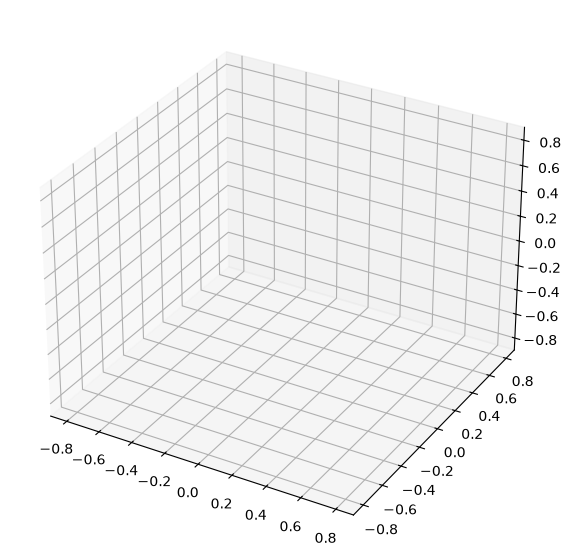

In [9]:
# Set up a 3D canvas, Bloch sphere, background musical vectors.

fig, ax = plt.subplots(subplot_kw=dict(projection="3d", computed_zorder=False), figsize=(7, 7))
b = Bloch(axes=ax)
b.plot_axes_labels = lambda: None # hide axes labels.

# Arrays for notes and colour mapping.
notes = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
octave_colours = [plt.colormaps["turbo_r"](val) for val in np.linspace(0, 1, 12)]

# Assign even spaced locations for each musical vector arrow.
octave = {}
for i in range(0, 12):
    r = 1
    theta = np.pi / 2 # octave at circumference.
    phi = (i / 6) * np.pi
    x, y, z = spherical_to_cartesian(r, theta, phi)
            
    octave[notes[i]] = [x, y, z]
    
# Sequentially add vectors and text annotations.
for label, coords in octave.items():
    b.add_vectors(coords)
        
    # Move labels 15% away from the sphere's centre.
    label_coords = 1.15 * np.array(coords)
    b.add_annotation(label_coords, label)

background_note_vectors = list(b.fixed_vectors) if hasattr(b, 'fixed_vectors') and b.fixed_vectors else list(b.vectors)
background_colors = octave_colours
background_width = 3

# Set up padding boundaries.
limit = 0.9
ax.set_xlim3d(-limit, limit)
ax.set_ylim3d(-limit, limit)
ax.set_zlim3d(-limit, limit)
(-0.9, 0.9)

In [19]:
# Overall composition configurations.
qubit_num = int(input("Please input number of qubits desired."))
instrument_names = str(input("Please input instruments as desired for each qubit, separated by spaces."))
instrument_list = instrument_names.split(' ')
tempo = int(input("Please enter composition tempo."))

MyMIDI = MIDIFile(qubit_num) # create MIDI file with track number = qubit number.
animations = [] # create list to store each qubit's Bloch animation.
qcs = [0] * qubit_num # create list to store each qubit's gate diagram.

for x in range(qubit_num):  
    
    # Obtain and apply gates for each qubit:
    gate_list0 = str(input(f"Please input gates as required for qubit {x+1}, separated by spaces."))
    gate_list = gate_list0.split(' ')
    states, qc = gates(gate_list)
    qcs[x] = qc
    notes = theta_and_phi(states)
    print(notes)

    # Build the audio:
    track = x # 0-indexed tracks for each note sequence.
    channel = x # 0-indexed channels for each instrument.
    time = 0
    current_time = 0 # monitor current location in music.
    volume = int(input("Please enter qubit volume (0 - 127).")) # 0-127, 127 being full volume.

    # Find instrument in dictionary and apply to channel.
    if instrument_list[x] in instrument_dict:
        instrument = instrument_dict[instrument_list[x]]
    else:
        print("Invalid instrument.")
        instrument = 0 # default instrument of piano.
    MyMIDI.addProgramChange(track,channel,time,instrument)

    # Create track with tempo.
    MyMIDI.addTrackName(track, time, f"track {x}")
    MyMIDI.addTempo(track, time, tempo)

    # User input note duration names.
    duration_names = input(f"Please enter {len(notes)} note types, separated by spaces.")
    duration_list = duration_names.split(' ')

    lengths = [] # duration lengths of notes to match with animation.
    for i in range(len(notes)):
        pitch = notes[i]
    
        if duration_list[i] in duration_dict:
            duration = duration_dict[duration_list[i]] # find durations in dictionary and apply to notes.
        else:
            print("Invalid duration.")
            duration = 1 # default duration of 1.
        
        MyMIDI.addNote(track,channel,pitch,current_time,duration,volume) # add note to track.
        current_time += duration # increase current time based on note duration.
        lengths.append(60 * duration / tempo) # BPM durations to seconds.

    # Build animation timeline to match note durations:
    base_step = min(lengths)
    timeline = []
    # Repeat frames as durations require.
    for state_idx, length in enumerate(lengths):
        repeats = int(round(length / base_step))
        timeline.extend([state_idx] * repeats)
    
    # Build the animation:
    ani = FuncAnimation(fig, update, frames=timeline, fargs=(states,), interval=base_step, blit=False)
    animations.append(ani) # store each qubit animation.

# Save as MIDI and separate GIFs:
MIDI_path = "bloch_midi_1.1.midi"
with open(MIDI_path, 'wb') as output_file:
    MyMIDI.writeFile(output_file)
    
for index, ani in enumerate(animations):
    gif_path = f"bloch_anim_1.1_q{index+1}.gif"
    ani.save(gif_path, writer='pillow', fps=1/base_step)
plt.close(fig)

Please input number of qubits desired. 2
Please input instruments as desired for each qubit, separated by spaces. violin harp
Please enter composition tempo. 85
Please input gates as required for qubit 1, separated by spaces. u u u u u u
Please enter required parameters for u, separated by spaces. 1.9635 3.6652 0.0000
Please enter required parameters for u, separated by spaces. 0.0000 3.1416 -3.6652
Please enter required parameters for u, separated by spaces. -0.3927 5.7596 -3.1416
Please enter required parameters for u, separated by spaces. 0.3927 2.0944 -5.7596
Please enter required parameters for u, separated by spaces. 0.0000 1.0472 -2.0944
Please enter required parameters for u, separated by spaces. -0.3927 3.6652 -1.0472


[79, 78, 71, 76, 74, 67]


Please enter qubit volume (0 - 127). 100
Please enter 6 note types, separated by spaces. crotchet crotchet crotchet crotchet crotchet crotchet
Please input gates as required for qubit 2, separated by spaces. u u u u u u u u u u u u
Please enter required parameters for u, separated by spaces. 1.178097 3.665191 0.000000
Please enter required parameters for u, separated by spaces. 0.392699 1.047198 -3.665191
Please enter required parameters for u, separated by spaces. 0.000000 5.759587 -1.047198
Please enter required parameters for u, separated by spaces. 0.000000 1.047198 -5.759587
Please enter required parameters for u, separated by spaces. 0.000000 5.759587 -1.047198
Please enter required parameters for u, separated by spaces. 0.000000 1.047198 -5.759587
Please enter required parameters for u, separated by spaces. 0.392699 0.523599 2.094395
Please enter required parameters for u, separated by spaces. 0.392699 1.047198 -3.665191
Please enter required parameters for u, separated by space

[55, 62, 71, 62, 71, 62, 55, 62, 71, 62, 71, 62]


Please enter qubit volume (0 - 127). 90
Please enter 12 note types, separated by spaces. quaver quaver quaver quaver quaver quaver quaver quaver quaver quaver quaver quaver


C:\Users\jessi\Downloads\qiskit\.venv\Lib\site-packages\matplotlib\animation.py:920: UserWarning: Animation was deleted without rendering anything. This is most likely not intended. To prevent deletion, assign the Animation to a variable, e.g. `anim`, that exists until you output the Animation using `plt.show()` or `anim.save()`.
  warnings.warn(


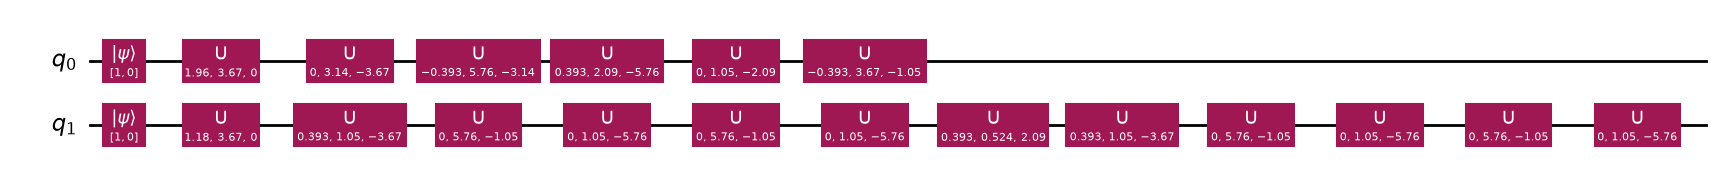

In [20]:
# Create a master circuit with N qubits.
master_qc = QuantumCircuit(len(qcs))

# Compose each 1-qubit circuit onto the master.
for qubit_idx, single_qc in enumerate(qcs):
    master_qc.compose(single_qc, qubits=[qubit_idx], inplace=True)

master_qc.draw('mpl')